# 1. Import libraries

In [1]:
import tensorflow as tf 
from tensorflow.keras import layers, models, datasets
import matplotlib.pyplot as plt 
import numpy as np 
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from collections import Counter

I0000 00:00:1779383948.797571   20041 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1779383951.185482   20041 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1779383991.730901   20041 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


# 2. Downloading and preparing the dataset 

In [2]:
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/keras/src/datasets/cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


In [3]:
x_train

array([[[[ 59,  62,  63],
         [ 43,  46,  45],
         [ 50,  48,  43],
         ...,
         [158, 132, 108],
         [152, 125, 102],
         [148, 124, 103]],

        [[ 16,  20,  20],
         [  0,   0,   0],
         [ 18,   8,   0],
         ...,
         [123,  88,  55],
         [119,  83,  50],
         [122,  87,  57]],

        [[ 25,  24,  21],
         [ 16,   7,   0],
         [ 49,  27,   8],
         ...,
         [118,  84,  50],
         [120,  84,  50],
         [109,  73,  42]],

        ...,

        [[208, 170,  96],
         [201, 153,  34],
         [198, 161,  26],
         ...,
         [160, 133,  70],
         [ 56,  31,   7],
         [ 53,  34,  20]],

        [[180, 139,  96],
         [173, 123,  42],
         [186, 144,  30],
         ...,
         [184, 148,  94],
         [ 97,  62,  34],
         [ 83,  53,  34]],

        [[177, 144, 116],
         [168, 129,  94],
         [179, 142,  87],
         ...,
         [216, 184, 140],
        

In [4]:
x_train.shape

(50000, 32, 32, 3)

In [5]:
y_flat = y_train.flatten()
class_counts = Counter(y_flat)

In [7]:
class_names = ['Airplane','Automobile','Bird','Cat','Deer','Dog','Frog','Horse','Ship','Truck']
num_classes = len(class_names)

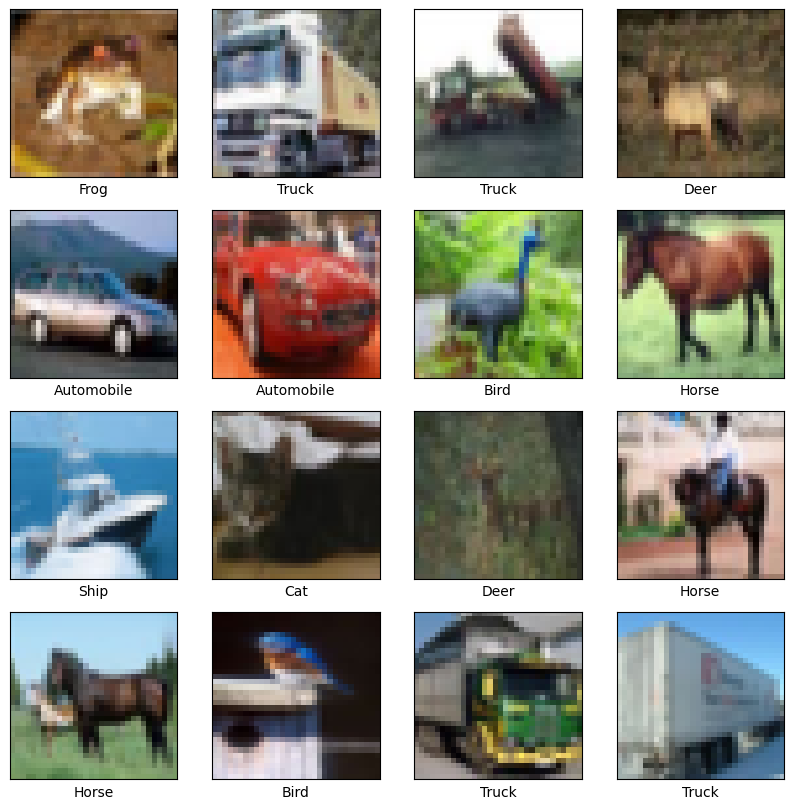

In [ ]:
plt.figure(figsize=(10,10))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(class_names[np.argmax(y_train[i])])
plt.show()

# 2. EDA - Exploratory Data Analysis

In [8]:
print("\n📊 Số ảnh mỗi class (train):")
for idx in range(num_classes):
    print(f"  [{idx:3d}] {class_names[idx]:<20s}: {class_counts[idx]} ảnh")


📊 Số ảnh mỗi class (train):
  [  0] Airplane            : 5000 ảnh
  [  1] Automobile          : 5000 ảnh
  [  2] Bird                : 5000 ảnh
  [  3] Cat                 : 5000 ảnh
  [  4] Deer                : 5000 ảnh
  [  5] Dog                 : 5000 ảnh
  [  6] Frog                : 5000 ảnh
  [  7] Horse               : 5000 ảnh
  [  8] Ship                : 5000 ảnh
  [  9] Truck               : 5000 ảnh


# 3. Preprocessing and normalizing the data 

In [9]:
rows, cols = 32, 32 
input_shape=(rows, cols, 3) 
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train = x_train/255.0 
x_test = x_test/255.0 
y_train=tf.keras.utils.to_categorical(y_train, 10)

In [10]:
y_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(50000, 10))

# 3. Build model 

In [11]:
def build_lenet1(input_shape):
    model = models.Sequential([
        layers.Conv2D(filters=32, strides=(1,1), kernel_size=(5,5), activation='tanh', input_shape=input_shape),
        layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)), 
        layers.Conv2D(filters=32, strides=(1,1), kernel_size=(5,5), activation='tanh'), 
        layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)),
        layers.Dense(units=120, activation='tanh'),
        layers.Flatten(),
        layers.Dense(units=84, activation='tanh'),
        layers.Dense(units=10, activation='softmax')
    ])
    return model 

In [12]:
lenet1 = build_lenet1(input_shape)
lenet1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
lenet1.summary()

/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1779384405.784238   20041 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 32)     │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 32)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5, 5, 120)      │         3,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │       252,084 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 284,958 (1.09 MB)

 Trainable params: 284,958 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
epochs = 20 
history1 = lenet1.fit(x_train, y_train, 
                     epochs=epochs, 
                     batch_size=128, 
                     callbacks=[early_stop, reduce_lr], 
                     validation_split=0.2, 
                     verbose=2)

Epoch 1/20


I0000 00:00:1779384442.761398   21532 service.cc:153] XLA service 0x7e49a40042e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1779384442.761466   21532 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1779384442.979083   21532 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1779384443.504455   21532 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1779384443.579812   21532 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2018__.28
I0000 00:00:1779384444.165272   21721 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_8', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1779384445.448034   21712 subprocess_compilation.cc:348] ptxas warnin

313/313 - 21s - 68ms/step - accuracy: 0.3544 - loss: 1.8357 - val_accuracy: 0.3772 - val_loss: 1.7696 - learning_rate: 0.0010
Epoch 2/20
313/313 - 5s - 15ms/step - accuracy: 0.4225 - loss: 1.6451 - val_accuracy: 0.4337 - val_loss: 1.5988 - learning_rate: 0.0010
Epoch 3/20
313/313 - 2s - 8ms/step - accuracy: 0.4695 - loss: 1.5113 - val_accuracy: 0.4691 - val_loss: 1.5045 - learning_rate: 0.0010
Epoch 4/20
313/313 - 2s - 7ms/step - accuracy: 0.5001 - loss: 1.4120 - val_accuracy: 0.4790 - val_loss: 1.4654 - learning_rate: 0.0010
Epoch 5/20
313/313 - 2s - 7ms/step - accuracy: 0.5203 - loss: 1.3535 - val_accuracy: 0.4986 - val_loss: 1.4230 - learning_rate: 0.0010
Epoch 6/20
313/313 - 2s - 7ms/step - accuracy: 0.5396 - loss: 1.2983 - val_accuracy: 0.5199 - val_loss: 1.3609 - learning_rate: 0.0010
Epoch 7/20
313/313 - 2s - 7ms/step - accuracy: 0.5577 - loss: 1.2544 - val_accuracy: 0.5281 - val_loss: 1.3448 - learning_rate: 0.0010
Epoch 8/20
313/313 - 2s - 7ms/step - accuracy: 0.5745 - loss: 1

In [14]:
if len(y_test.shape) != 2 or y_test.shape[1] != 10:
  y_test = tf.keras.utils.to_categorical(y_test, 10)

loss ,acc= lenet1.evaluate(x_test, y_test, verbose=0)
print('Accuracy : ', acc)
print('Loss: ', loss)

Accuracy :  0.5781999826431274
Loss:  1.2270123958587646


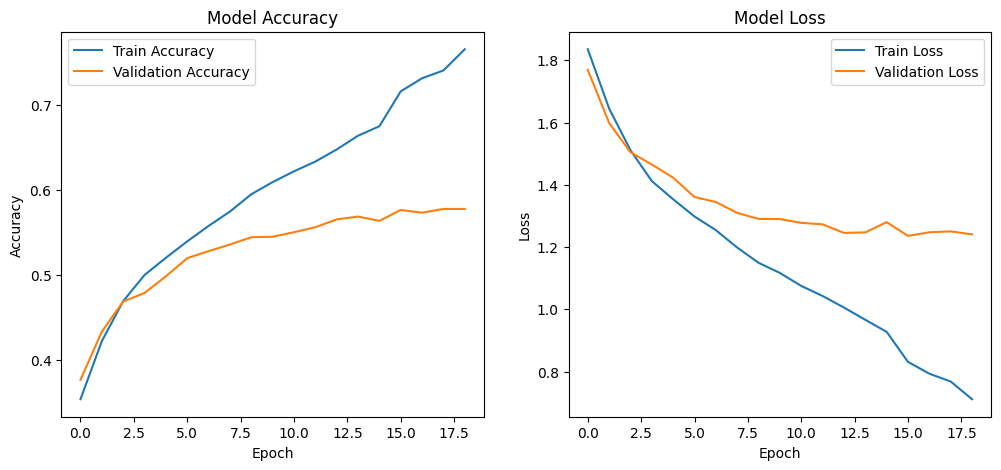

In [15]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(history1.history['accuracy'], label='Train Accuracy')
plt.plot(history1.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history1.history['loss'], label='Train Loss')
plt.plot(history1.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 920ms/step


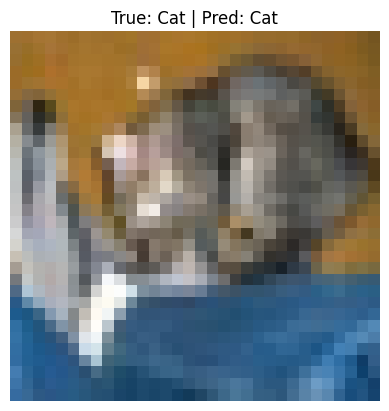

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


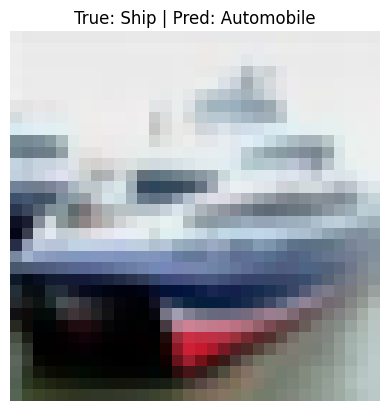

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


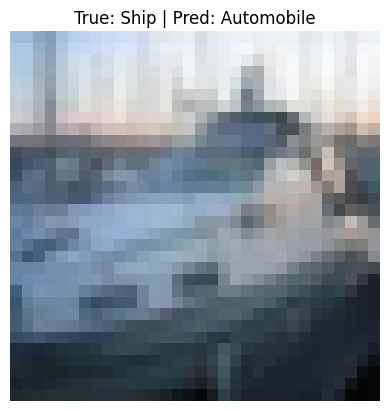

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


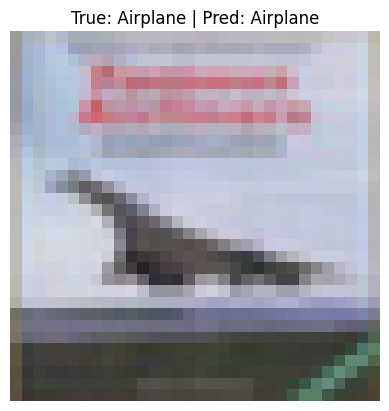

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


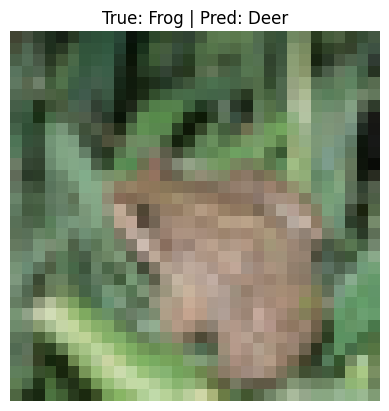

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


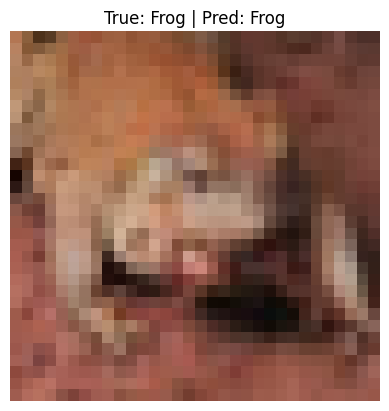

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


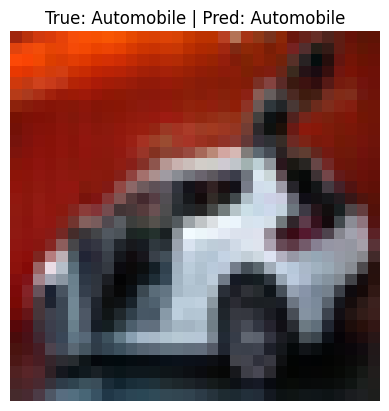

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


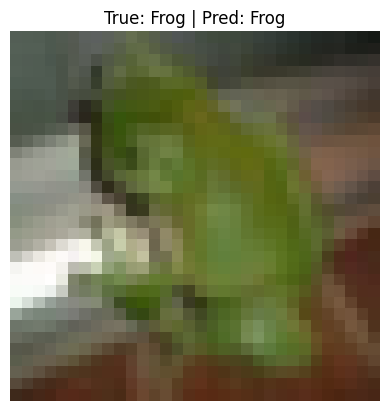

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


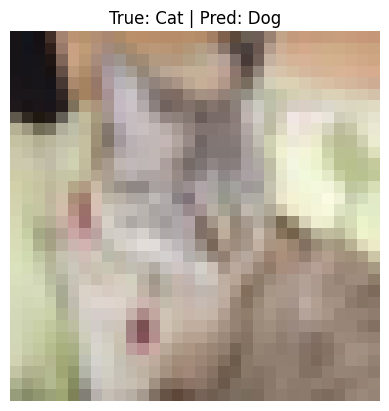

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


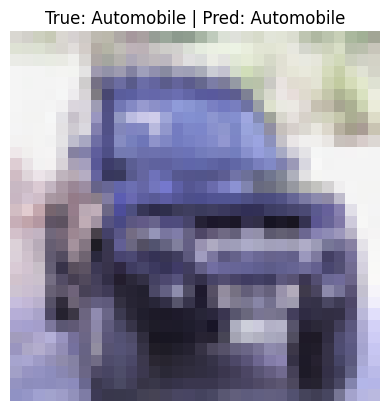

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


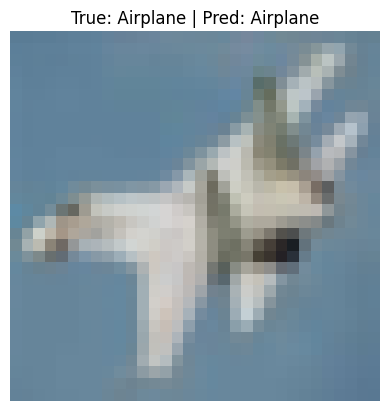

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


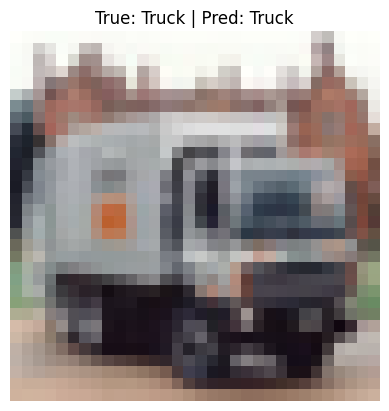

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


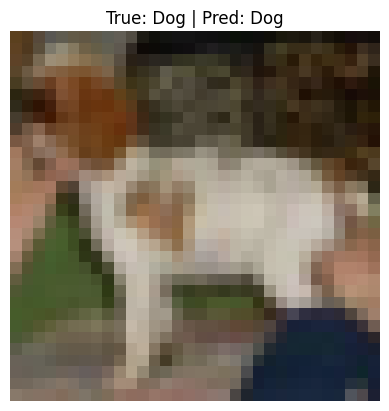

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


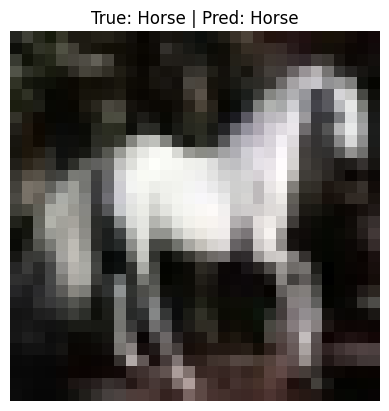

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


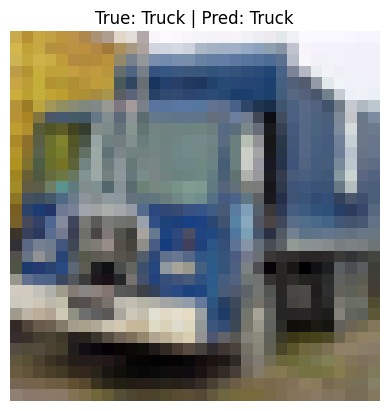

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


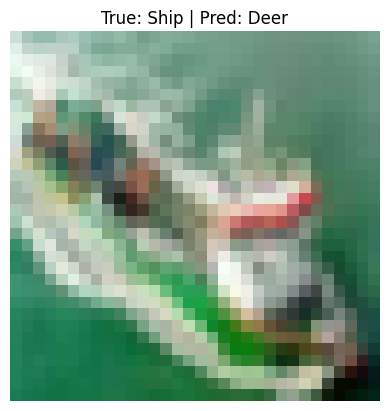

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


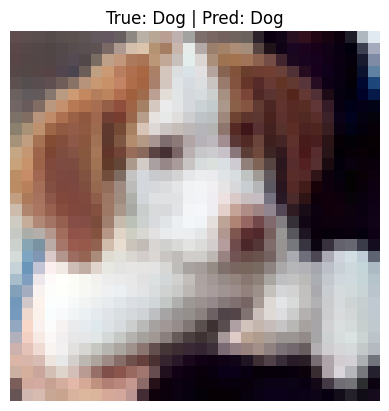

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


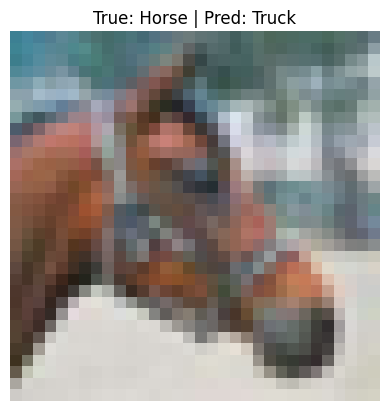

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


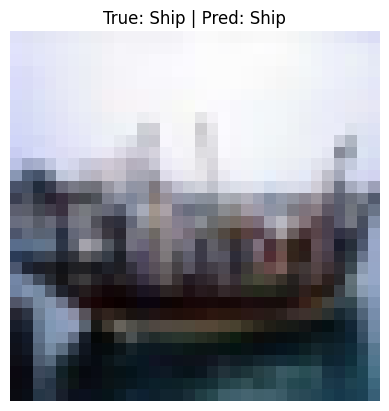

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


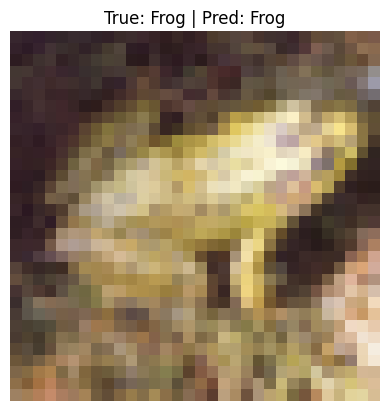

In [16]:
def plot_predictions(index):
    img = x_test[index]
    true_label = class_names[np.argmax(y_test[index])]
    pred_probs = lenet1.predict(np.expand_dims(img, axis=0))
    pred_label = class_names[np.argmax(pred_probs)]
    
    plt.imshow(img)
    plt.title(f"True: {true_label} | Pred: {pred_label}")
    plt.axis('off')
    plt.show()


for i in range(20):
    plot_predictions(i)

In [17]:
lenet1.save("../data/models/lenet1_cifar10.h5") 

In [ ]:
def build_lenet2(input_shape):
    model = models.Sequential([
        # C1 Layer 
        layers.Conv2D(filters=32, strides=(1,1), kernel_size=(5,5), activation='tanh', input_shape=input_shape),
        # S2 Layer
        layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)), 
        # C3 layer
        layers.Conv2D(filters=32, strides=(1,1), kernel_size=(5,5), activation='tanh'), 
        #S4 layer 
        layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)),
        # C5 layer 
        layers.Dense(units=256, activation='tanh'),
        layers.Flatten(),
        # C6 layer 
        layers.Dense(units=128, activation='tanh'),
        # C7 Output layer 
        layers.Dense(units=10, activation='softmax')
    ])
    return model 

In [19]:
lenet2 = build_lenet2(input_shape)
lenet2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
lenet2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 14, 14, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 32)     │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (None, 5, 5, 32)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5, 5, 256)      │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       819,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 857,130 (3.27 MB)

 Trainable params: 857,130 (3.27 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
epochs = 20 
history2 = lenet2.fit(x_train, y_train, 
                     epochs=epochs, 
                     batch_size=128, 
                     callbacks=[early_stop, reduce_lr], 
                     validation_split=0.2, 
                     verbose=2)

Epoch 1/20


I0000 00:00:1779384713.985095   21531 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_37617__.28
I0000 00:00:1779384719.822102   21533 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_37617__.28


313/313 - 12s - 39ms/step - accuracy: 0.3491 - loss: 1.8456 - val_accuracy: 0.3750 - val_loss: 1.7935 - learning_rate: 0.0010
Epoch 2/20
313/313 - 3s - 9ms/step - accuracy: 0.4103 - loss: 1.6883 - val_accuracy: 0.4095 - val_loss: 1.6654 - learning_rate: 0.0010
Epoch 3/20
313/313 - 3s - 8ms/step - accuracy: 0.4595 - loss: 1.5397 - val_accuracy: 0.4644 - val_loss: 1.5293 - learning_rate: 0.0010
Epoch 4/20
313/313 - 2s - 8ms/step - accuracy: 0.4953 - loss: 1.4358 - val_accuracy: 0.4836 - val_loss: 1.4699 - learning_rate: 0.0010
Epoch 5/20
313/313 - 2s - 8ms/step - accuracy: 0.5174 - loss: 1.3651 - val_accuracy: 0.4953 - val_loss: 1.4417 - learning_rate: 0.0010
Epoch 6/20
313/313 - 2s - 7ms/step - accuracy: 0.5316 - loss: 1.3297 - val_accuracy: 0.5033 - val_loss: 1.4139 - learning_rate: 0.0010
Epoch 7/20
313/313 - 2s - 7ms/step - accuracy: 0.5453 - loss: 1.2929 - val_accuracy: 0.4999 - val_loss: 1.4237 - learning_rate: 0.0010
Epoch 8/20
313/313 - 3s - 8ms/step - accuracy: 0.5580 - loss: 1.

In [21]:
if len(y_test.shape) != 2 or y_test.shape[1] != 10:
  y_test = tf.keras.utils.to_categorical(y_test, 10)

loss ,acc= lenet2.evaluate(x_test, y_test, verbose=0)
print('Accuracy : ', acc)
print('Loss: ', loss)

Accuracy :  0.5238000154495239
Loss:  1.3501306772232056


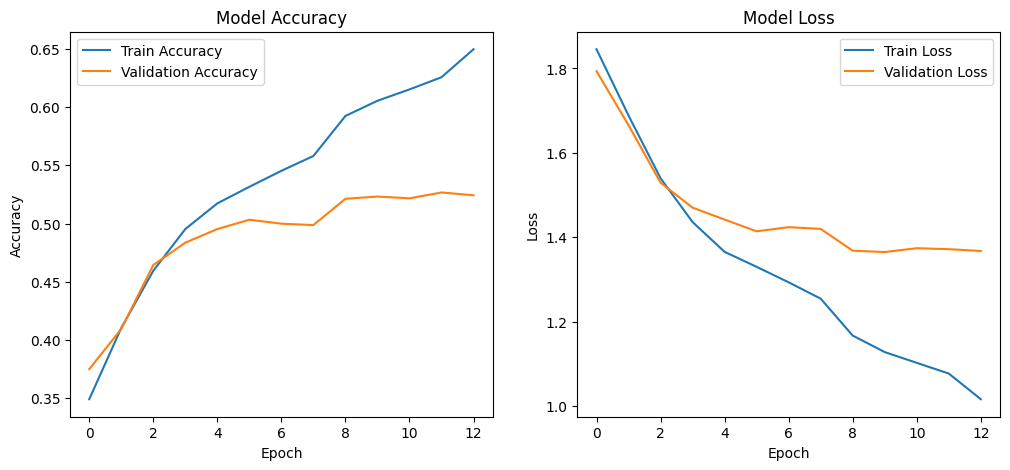

In [22]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(history2.history['accuracy'], label='Train Accuracy')
plt.plot(history2.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history2.history['loss'], label='Train Loss')
plt.plot(history2.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 569ms/step


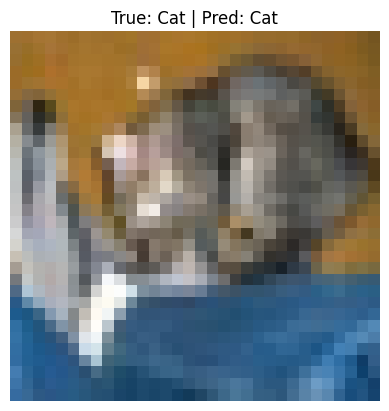

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


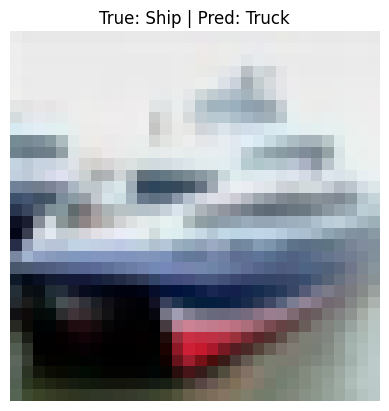

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


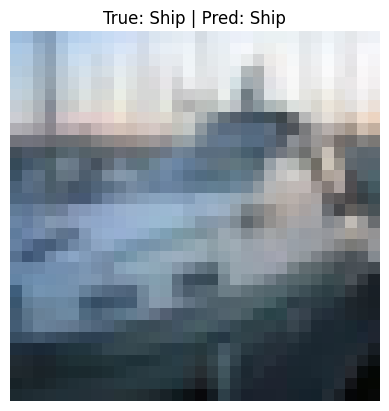

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


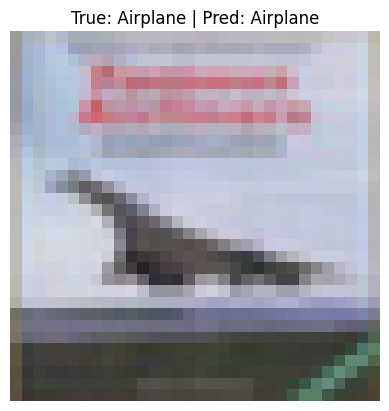

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


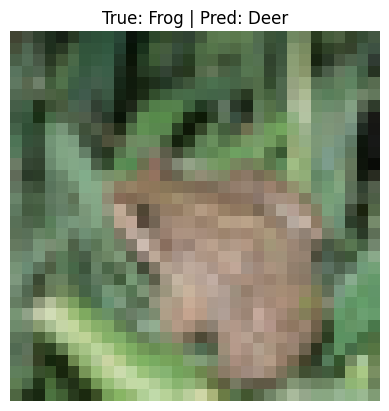

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


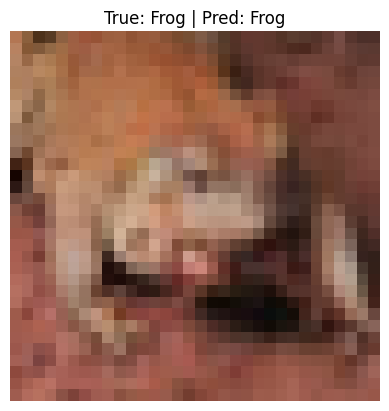

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


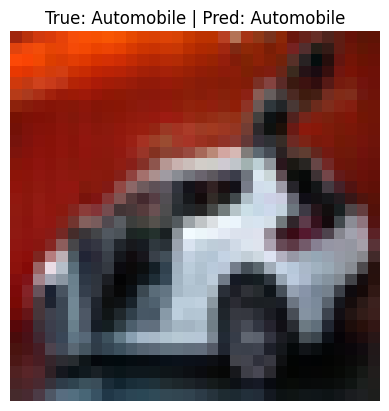

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


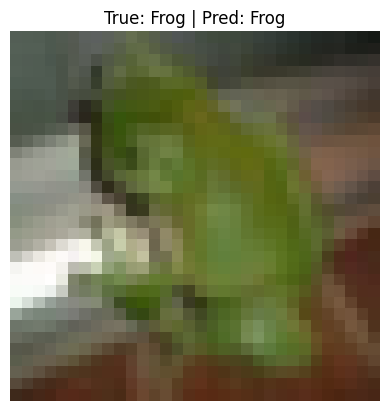

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


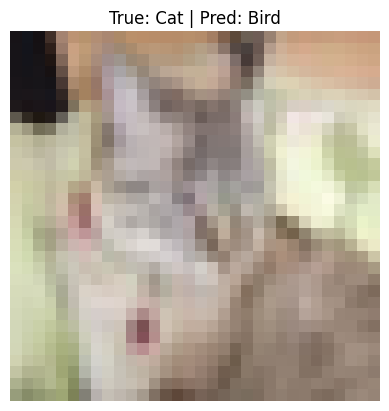

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


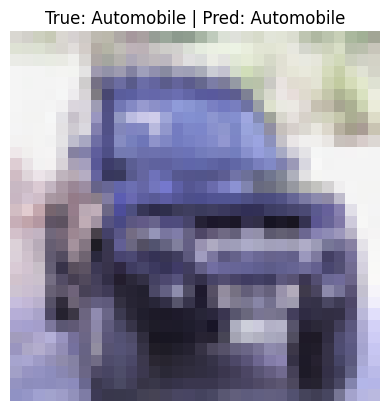

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


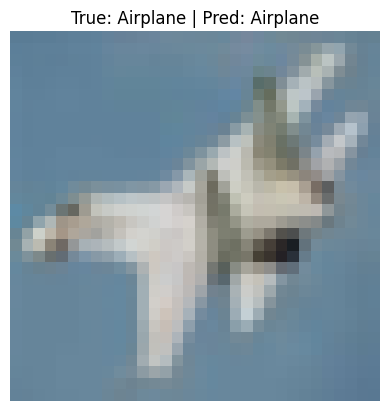

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


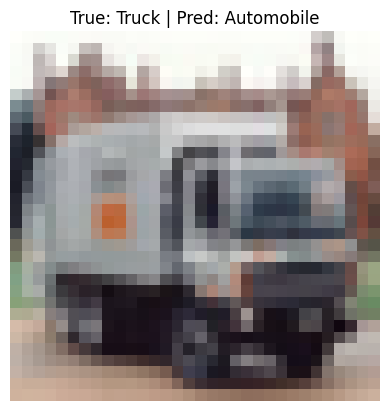

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


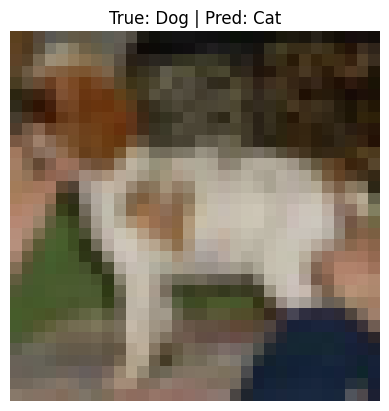

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


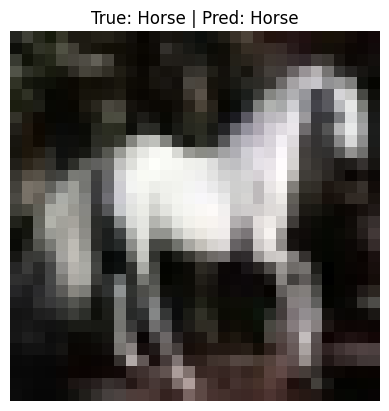

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


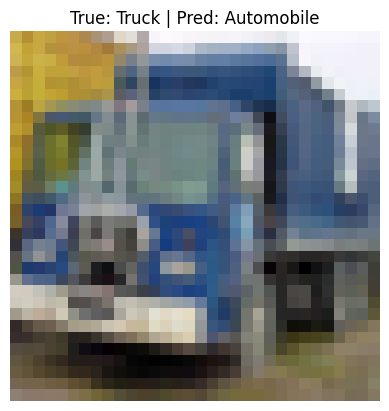

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


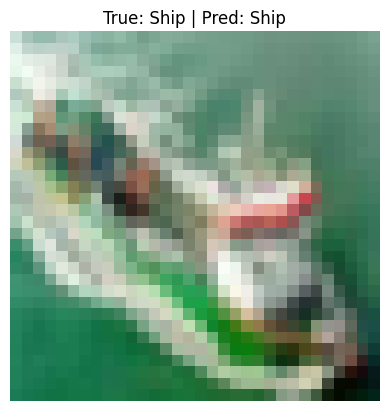

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


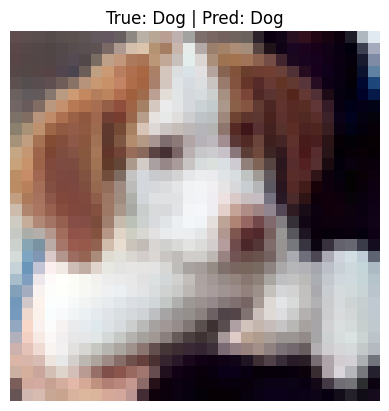

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


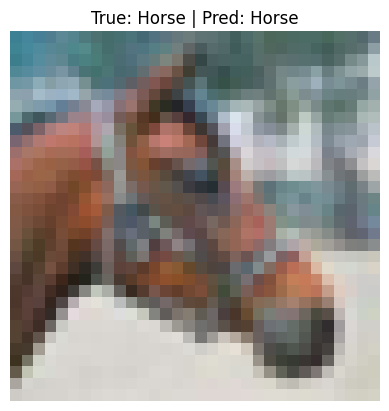

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


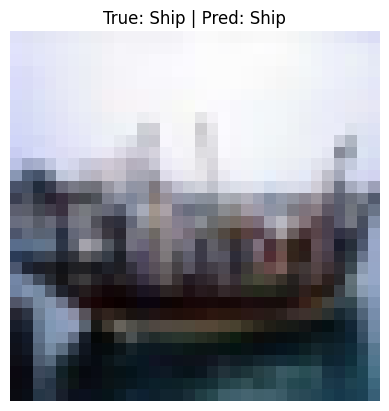

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


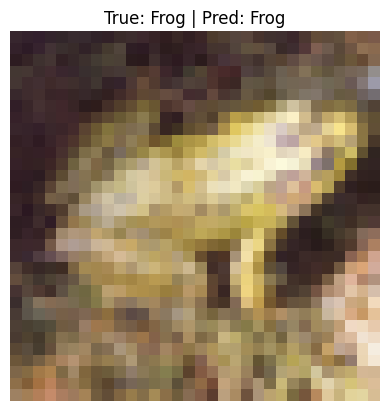

In [23]:
def plot_predictions2(index):
    img = x_test[index]
    true_label = class_names[np.argmax(y_test[index])]
    pred_probs = lenet2.predict(np.expand_dims(img, axis=0))
    pred_label = class_names[np.argmax(pred_probs)]
    
    plt.imshow(img)
    plt.title(f"True: {true_label} | Pred: {pred_label}")
    plt.axis('off')
    plt.show()


for i in range(20):
    plot_predictions2(i)